# Q10 - Creative Agent: Expanding Search and Action Space with RL

Same code as `q10_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q10 - Utility-based agent + reinforcement learning that EXPANDS its action space.

The agent designs a phone by choosing features one step at a time (6 slots, 4 options each).
A hidden synergy rewards certain feature PAIRS, which single-feature actions reach slowly.
After a warm-up the agent mines its best action pairs into macro-actions (new actions),
so the action space and the reachable search space both grow.
"""
import os
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np

os.makedirs("images", exist_ok=True)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

SLOTS = ["screen", "battery", "camera", "body", "sensors", "ai"]
N_OPT, STEPS, EPISODES, EXPAND_AT = 4, 3, 1500, 500
BASE = [(s, o) for s in range(6) for o in range(N_OPT)]  # 24 single-feature actions
BASE_UTIL = np.random.default_rng(3).uniform(0.2, 0.6, (6, N_OPT))
SYNERGY = {((2, 3), (5, 3)): 3.0, ((1, 2), (4, 1)): 2.5, ((0, 1), (3, 2)): 2.0}  # hidden pair bonuses


def utility(design: dict) -> float:
    """Utility = feature quality + synergy bonuses - cost of changing many slots."""
    u = sum(BASE_UTIL[s, o] for s, o in design.items())
    for (a, b), bonus in SYNERGY.items():
        if design.get(a[0]) == a[1] and design.get(b[0]) == b[1]:
            u += bonus
    return u


def expand_actions(actions: list, good_runs: list, top: int = 4) -> list:
    """Creative step: turn the most frequent successful action PAIRS into new macro-actions."""
    pairs = Counter(p for run in good_runs for p in zip(run, run[1:]))
    return actions + [(a, b) for (a, b), _ in pairs.most_common(top) if (a, b) not in actions]


def run_episode(q: dict, actions: list, eps: float, alpha: float, rng) -> tuple:
    design, taken, steps_used = {}, [], 0
    state = frozenset()
    for _ in range(STEPS):
        legal = [i for i, a in enumerate(actions)
                 if all(s not in design for s, _ in (a if isinstance(a[0], tuple) else (a,)))]
        if not legal:
            break
        pick = (rng.choice(legal) if rng.random() < eps
                else max(legal, key=lambda i: q.get((state, i), 0.0) + 1e-6 * rng.random()))
        act = actions[pick]
        for s, o in (act if isinstance(act[0], tuple) else (act,)):
            design[s] = o
        taken.append((state, pick, act))
        state = frozenset(design.items())
    reward = utility(design)
    for st, pick, _ in taken:  # Monte-Carlo update toward the final utility
        q[(st, pick)] = q.get((st, pick), 0.0) + alpha * (reward - q.get((st, pick), 0.0))
    return reward, [a for _, _, a in taken], design


def train(expand: bool, seed: int = 4) -> dict:
    rng = np.random.default_rng(seed)
    actions, q, returns, sizes, best_runs = list(BASE), {}, [], [], []
    for ep in range(1, EPISODES + 1):
        if expand and ep == EXPAND_AT + 1:  # creative expansion of the action space
            top_runs = sorted(best_runs, key=lambda r: -r[0])[:60]
            actions = expand_actions(actions, [r[1] for r in top_runs])
            q = {}
        eps = max(0.05, 0.5 * (1 - ((ep - 1) % EXPAND_AT if expand else ep - 1) / EXPAND_AT))
        reward, taken, design = run_episode(q, actions, eps, 0.1, rng)
        best_runs.append((reward, [a for a in taken if not isinstance(a[0], tuple)]))
        returns.append(reward)
        sizes.append(len(actions))
    return {"returns": np.array(returns), "sizes": sizes, "actions": actions, "q": q}


def greedy_value(res: dict) -> float:
    rng = np.random.default_rng(0)
    return float(np.mean([run_episode(dict(res["q"]), res["actions"], 0.0, 0.0, rng)[0] for _ in range(50)]))


plain, creative = train(False), train(True)
best_possible = max(utility({0: a, 1: b, 2: c}) for a in range(4) for b in range(4) for c in range(4))
print("Q10  Utility-based agent + RL that expands its action space (design a phone)")
print(f"Basic actions: {len(BASE)} | steps per design: {STEPS} | expansion at episode {EXPAND_AT}")
print(f"Action space: {len(plain['actions'])} -> {len(creative['actions'])} actions "
      f"(+{len(creative['actions']) - len(BASE)} macro-actions)")
print("New macro-actions (found by the agent, each = 2 features in 1 step):")
for a in creative["actions"][len(BASE):]:
    print("  " + " + ".join(f"{SLOTS[s]}={o}" for s, o in a))
for lo, hi in [(0, 500), (500, 1000), (1000, 1500)]:
    print(f"Avg utility, episodes {lo + 1:>4}-{hi:<4}: plain {plain['returns'][lo:hi].mean():.2f}"
          f" | creative {creative['returns'][lo:hi].mean():.2f}")
print(f"Final greedy design utility: plain {greedy_value(plain):.2f} | creative "
      f"{greedy_value(creative):.2f}")

# ---------------- charts ----------------
def smooth(x: np.ndarray, w: int = 50) -> np.ndarray:
    return np.convolve(x, np.ones(w) / w, mode="valid")


fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
for res, name, colour in [(plain, "fixed 24 actions", "#9ca3af"), (creative, "with action-space expansion", "#e76f51")]:
    a1.plot(np.arange(50, EPISODES + 1), smooth(res["returns"]), color=colour, lw=2, label=name)
a1.axvline(EXPAND_AT, color="#2a9d8f", ls="--")
a1.text(EXPAND_AT + 20, 5.2, "macro-actions\nadded", color="#2a9d8f", fontsize=8.5)
a1.set_xlabel("episode")
a1.set_ylabel("utility (50-episode average)")
a1.set_title("Learning curve of the utility-based RL agent")
a1.legend(fontsize=8, loc="upper left")
a2.step(range(1, EPISODES + 1), creative["sizes"], color="#e76f51", lw=2, label="creative agent")
a2.step(range(1, EPISODES + 1), plain["sizes"], color="#9ca3af", lw=2, label="fixed agent")
a2.axvline(EXPAND_AT, color="#2a9d8f", ls="--")
a2.set_ylim(20, 32)
a2.set_xlabel("episode")
a2.set_ylabel("number of actions available")
a2.set_title("Action-space size over time")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q10_chart1_learning_curve.png")
plt.close(fig)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
labels = ["fixed actions", "with expansion"]
vals = [greedy_value(plain), greedy_value(creative)]
ax.bar(labels, vals, color=["#9ca3af", "#e76f51"], width=0.5)
for i, v in enumerate(vals):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center", fontweight="bold")
ax.set_ylabel("utility of the final greedy design")
ax.set_title("Same 3 design steps, better product after expansion")
fig.tight_layout()
fig.savefig("images/q10_chart2_final_utility.png")
plt.close(fig)
print("charts saved to images/")


Q10  Utility-based agent + RL that expands its action space (design a phone)
Basic actions: 24 | steps per design: 3 | expansion at episode 500
Action space: 24 -> 28 actions (+4 macro-actions)
New macro-actions (found by the agent, each = 2 features in 1 step):
  body=2 + screen=1
  screen=1 + ai=2
  battery=2 + sensors=1
  body=2 + battery=2
Avg utility, episodes    1-500 : plain 1.92 | creative 1.92
Avg utility, episodes  501-1000: plain 2.92 | creative 3.13
Avg utility, episodes 1001-1500: plain 2.98 | creative 4.68
Final greedy design utility: plain 3.11 | creative 6.46


charts saved to images/


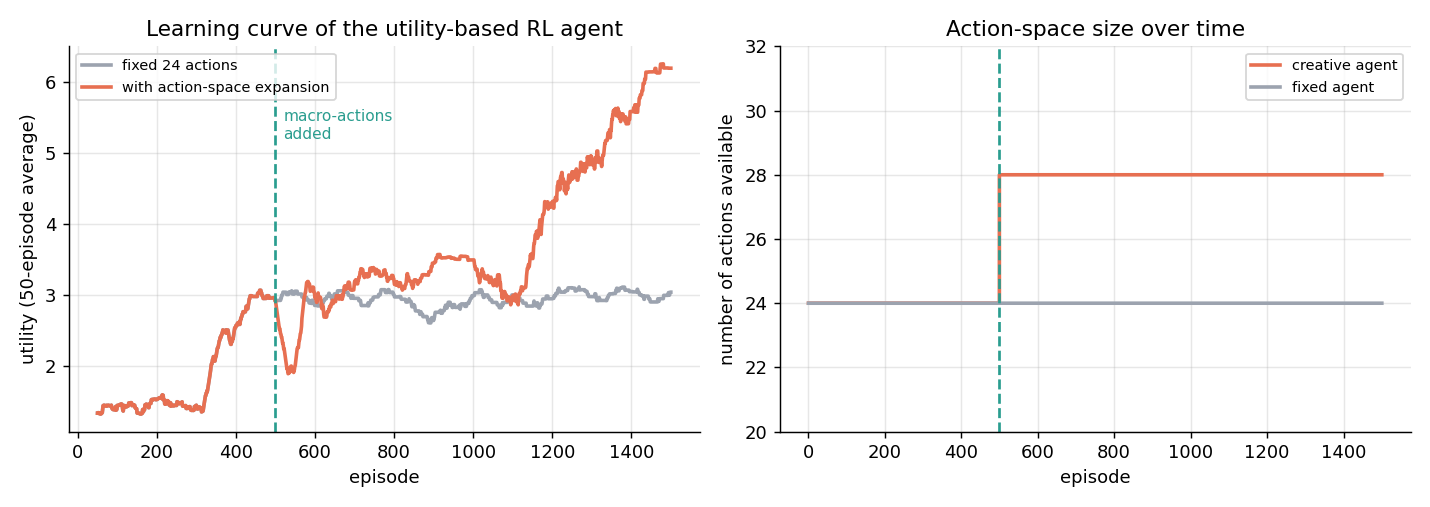

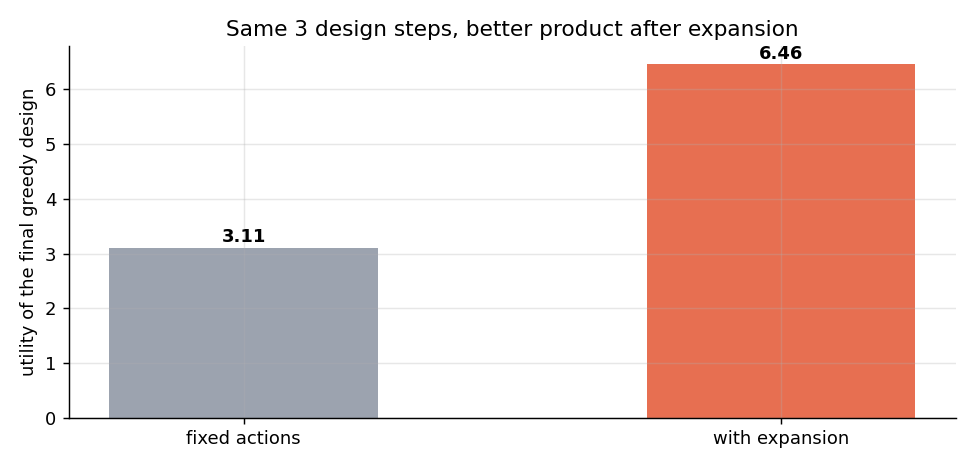

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q10_chart*.png')):
    display(Image(p))